Amazon Product Data Analysis(EDA)
#Exploratory Data Analysis of Amazon Products

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from pathlib import Path
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns",50)
DATA_PATH="/content/amazon.csv"
df=pd.read_csv(DATA_PATH,encoding="utf-8")
print("dataset loaded")
print("Shape:",df.shape)
display(df.head())

dataset loaded
Shape: (1465, 16)


,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,user_id,user_name,review_id,review_title,review_content,img_link,product_link
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,₹399,"₹1,099",64%,4.2,"24,269",High Compatibility : Compatible With iPhone 12...,"AG3D6O4STAQKAY2UVGEUV46KN35Q,AHMY5CWJMMK5BJRBB...","Manav,Adarsh gupta,Sundeep,S.Sayeed Ahmed,jasp...","R3HXWT0LRP0NMF,R2AJM3LFTLZHFO,R6AQJGUP6P86,R1K...","Satisfied,Charging is really fast,Value for mo...",Looks durable Charging is fine tooNo complains...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...
1,B098NS6PVG,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories|Accessories&Peripherals|...,₹199,₹349,43%,4.0,"43,994","Compatible with all Type C enabled devices, be...","AECPFYFQVRUWC3KGNLJIOREFP5LQ,AGYYVPDD7YG7FYNBX...","ArdKn,Nirbhay kumar,Sagar Viswanathan,Asp,Plac...","RGIQEG07R9HS2,R1SMWZQ86XIN8U,R2J3Y1WL29GWDE,RY...","A Good Braided Cable for Your Type C Device,Go...",I ordered this cable to connect my phone to An...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Ambrane-Unbreakable-Char...
2,B096MSW6CT,Sounce Fast Phone Charging Cable & Data Sync U...,Computers&Accessories|Accessories&Peripherals|...,₹199,"₹1,899",90%,3.9,"7,928",【 Fast Charger& Data Sync】-With built-in safet...,"AGU3BBQ2V2DDAMOAKGFAWDDQ6QHA,AESFLDV2PT363T2AQ...","Kunal,Himanshu,viswanath,sai niharka,saqib mal...","R3J3EQQ9TZI5ZJ,R3E7WBGK7ID0KV,RWU79XKQ6I1QF,R2...","Good speed for earlier versions,Good Product,W...","Not quite durable and sturdy,https://m.media-a...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Sounce-iPhone-Charging-C...
3,B08HDJ86NZ,boAt Deuce USB 300 2 in 1 Type-C & Micro USB S...,Computers&Accessories|Accessories&Peripherals|...,₹329,₹699,53%,4.2,"94,363",The boAt Deuce USB 300 2 in 1 cable is compati...,"AEWAZDZZJLQUYVOVGBEUKSLXHQ5A,AG5HTSFRRE6NL3M5S...","Omkar dhale,JD,HEMALATHA,Ajwadh a.,amar singh ...","R3EEUZKKK9J36I,R3HJVYCLYOY554,REDECAZ7AMPQC,R1...","Good product,Good one,Nice,Really nice product...","Good product,long wire,Charges good,Nice,I bou...",https://m.media-amazon.com/images/I/41V5FtEWPk...,https://www.amazon.in/Deuce-300-Resistant-Tang...
4,B08CF3B7N1,Portronics Konnect L 1.2M Fast Charging 3A 8 P...,Computers&Accessories|Accessories&Peripherals|...,₹154,₹399,61%,4.2,"16,905",[CHARGE & SYNC FUNCTION]- This cable comes wit...,"AE3Q6KSUK5P75D5HFYHCRAOLODSA,AFUGIFH5ZAFXRDSZH...","rahuls6099,Swasat Borah,Ajay Wadke,Pranali,RVK...","R1BP4L2HH9TFUP,R16PVJEXKV6QZS,R2UPDB81N66T4P,R...","As good as original,Decent,Good one for second...","Bought this instead of original apple, does th...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Portronics-Konnect-POR-1...


In [ ]:
print(df.shape)
print(df.columns)
print(df.info())

(1465, 16)
Index(['product_id', 'product_name', 'category', 'discounted_price',
       'actual_price', 'discount_percentage', 'rating', 'rating_count',
       'about_product', 'user_id', 'user_name', 'review_id', 'review_title',
       'review_content', 'img_link', 'product_link'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1465 entries, 0 to 1464
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   product_id           1465 non-null   object 
 1   product_name         1465 non-null   object 
 2   category             1465 non-null   object 
 3   discounted_price     1465 non-null   object 
 4   actual_price         1465 non-null   object 
 5   discount_percentage  1465 non-null   object 
 6   rating               1465 non-null   float64
 7   rating_count         1465 non-null   float64
 8   about_product        1465 non-null   object 
 9   user_id              1465 non-nul

In [ ]:
display(df.describe())
display(df.describe(include="object"))



,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,user_id,user_name,review_id,review_title,review_content,img_link,product_link
count,1465,1465,1465,1465,1465,1465,1465,1463,1465,1465,1465,1465,1465,1465,1465,1465
unique,1351,1337,211,550,449,92,28,1143,1293,1194,1194,1194,1194,1212,1412,1465
top,B083342NKJ,"Fire-Boltt Ninja Call Pro Plus 1.83"" Smart Wat...",Computers&Accessories|Accessories&Peripherals|...,₹199,₹999,50%,4.1,"9,378",[CHARGE & SYNC FUNCTION]- This cable comes wit...,"AHIKJUDTVJ4T6DV6IUGFYZ5LXMPA,AE55KTFVNXYFD5FPY...","$@|\|TO$|-|,Sethu madhav,Akash Thakur,Burger P...","R3F4T5TRYPTMIG,R3DQIEC603E7AY,R1O4Z15FD40PV5,R...","Worked on iPhone 7 and didn’t work on XR,Good ...","I am not big on camera usage, personally. I wa...",https://m.media-amazon.com/images/I/413sCRKobN...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...
freq,3,5,233,53,120,56,244,9,6,10,10,10,10,8,3,1


,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,user_id,user_name,review_id,review_title,review_content,img_link,product_link
count,1465,1465,1465,1465,1465,1465,1465,1463,1465,1465,1465,1465,1465,1465,1465,1465
unique,1351,1337,211,550,449,92,28,1143,1293,1194,1194,1194,1194,1212,1412,1465
top,B083342NKJ,"Fire-Boltt Ninja Call Pro Plus 1.83"" Smart Wat...",Computers&Accessories|Accessories&Peripherals|...,₹199,₹999,50%,4.1,"9,378",[CHARGE & SYNC FUNCTION]- This cable comes wit...,"AHIKJUDTVJ4T6DV6IUGFYZ5LXMPA,AE55KTFVNXYFD5FPY...","$@|\|TO$|-|,Sethu madhav,Akash Thakur,Burger P...","R3F4T5TRYPTMIG,R3DQIEC603E7AY,R1O4Z15FD40PV5,R...","Worked on iPhone 7 and didn’t work on XR,Good ...","I am not big on camera usage, personally. I wa...",https://m.media-amazon.com/images/I/413sCRKobN...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...
freq,3,5,233,53,120,56,244,9,6,10,10,10,10,8,3,1


In [ ]:
df.dtypes

,0
product_id,object
product_name,object
category,object
discounted_price,object
actual_price,object
discount_percentage,object
rating,object
rating_count,object
about_product,object
user_id,object


In [ ]:

print("Missing Values")
print(df.isnull().sum())
print("\nTotal missing values")
print(df.isnull().sum().sum())

Missing Values
product_id             0
product_name           0
category               0
discounted_price       0
actual_price           0
discount_percentage    0
rating                 1
rating_count           0
about_product          0
user_id                0
user_name              0
review_id              0
review_title           0
review_content         0
img_link               0
product_link           0
price_difference       0
savings_percentage     0
main_category          0
sub_category           0
dtype: int64

Total missing values
1


In [ ]:
# Total Duplicate Rows
print("Total Duplicate Rows:", df.duplicated().sum())

# Duplicate Product IDs
print("Duplicate Product IDs:",
      df['product_id'].duplicated().sum())

# Display Duplicate Rows
duplicates = df[df.duplicated(keep=False)]

display(duplicates.head())

Total Duplicate Rows: 0
Duplicate Product IDs: 114


,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,user_id,user_name,review_id,review_title,review_content,img_link,product_link,price_difference,savings_percentage,main_category,sub_category


In [ ]:
print(df.isnull().sum())
print("Total Missing Values:", df.isnull().sum().sum())
missing_percentage = (
    df.isnull().sum() / len(df)
) * 100

display(missing_percentage)

product_id             0
product_name           0
category               0
discounted_price       0
actual_price           0
discount_percentage    0
rating                 1
rating_count           0
about_product          0
user_id                0
user_name              0
review_id              0
review_title           0
review_content         0
img_link               0
product_link           0
price_difference       0
savings_percentage     0
main_category          0
sub_category           0
dtype: int64
Total Missing Values: 1


,0
product_id,0.000000
product_name,0.000000
category,0.000000
discounted_price,0.000000
actual_price,0.000000
discount_percentage,0.000000
rating,0.068259
rating_count,0.000000
about_product,0.000000
user_id,0.000000


In [3]:
print("Missing Values:")
print(df.isnull().sum())

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

Missing Values:
product_id             0
product_name           0
category               0
discounted_price       0
actual_price           0
discount_percentage    0
rating                 0
rating_count           2
about_product          0
user_id                0
user_name              0
review_id              0
review_title           0
review_content         0
img_link               0
product_link           0
dtype: int64

Total Missing Values:
2


In [ ]:
print("Missing Ratings:", df['rating'].isnull().sum())

print("Rating Median:", df['rating'].median())

print("Rating Mean:", df['rating'].mean())

Missing Ratings: 1
Rating Median: 4.1
Rating Mean: 4.096584699453552


In [ ]:
df['rating'].fillna(df['rating'].median(), inplace=True)

/tmp/ipykernel_528/333645285.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['rating'].fillna(df['rating'].median(), inplace=True)


In [ ]:
df.isnull().sum()

,0
product_id,0
product_name,0
category,0
discounted_price,0
actual_price,0
discount_percentage,0
rating,0
rating_count,0
about_product,0
user_id,0


In [ ]:
print("Duplicate Rows:", df.duplicated().sum())

print("Duplicate Product IDs:",
      df['product_id'].duplicated().sum())

Duplicate Rows: 0
Duplicate Product IDs: 114


In [ ]:
df["category"].value_counts().head()

,count
category,
Computers&Accessories|Accessories&Peripherals|Cables&Accessories|Cables|USBCables,233
Electronics|WearableTechnology|SmartWatches,76
Electronics|Mobiles&Accessories|Smartphones&BasicMobiles|Smartphones,68
"Electronics|HomeTheater,TV&Video|Televisions|SmartTelevisions",63
"Electronics|Headphones,Earbuds&Accessories|Headphones|In-Ear",52


In [ ]:
df['rating'].unique()

array(['4.2', '4.0', '3.9', '4.1', '4.3', '4.4', '4.5', '3.7', '3.3',
       '3.6', '3.4', '3.8', '3.5', '4.6', '3.2', '5.0', '4.7', '3.0',
       '2.8', '4', '3.1', '4.8', '2.3', '|', '2', '3', '2.6', '2.9'],
      dtype=object)

In [ ]:
df['rating'] = pd.to_numeric(
    df['rating'].replace('|', np.nan),
    errors='coerce'
)

In [ ]:
df['discounted_price'] = (
    df['discounted_price']
    .str.replace('₹', '', regex=False)
    .str.replace(',', '', regex=False)
    .astype(float)
)

df['actual_price'] = (
    df['actual_price']
    .str.replace('₹', '', regex=False)
    .str.replace(',', '', regex=False)
    .astype(float)
)

In [ ]:
df['discount_percentage'] = (
    df['discount_percentage']
    .str.replace('%', '', regex=False)
    .astype(float)
)

In [ ]:
df['price_difference'] = (
    df['actual_price'] - df['discounted_price']
)

In [ ]:
df['savings_percentage'] = (
    df['price_difference'] / df['actual_price']
) * 100

In [ ]:
df[['actual_price', 'discounted_price',
    'discount_percentage', 'price_difference',
    'savings_percentage']].head()

,actual_price,discounted_price,discount_percentage,price_difference,savings_percentage
0,1099.0,399.0,64.0,700.0,63.694268
1,349.0,199.0,43.0,150.0,42.979943
2,1899.0,199.0,90.0,1700.0,89.520800
3,699.0,329.0,53.0,370.0,52.932761
4,399.0,154.0,61.0,245.0,61.403509


In [ ]:
df['main_category'] = df['category'].str.split('|').str[0]

df['sub_category'] = df['category'].str.split('|').str[1]

df[['category', 'main_category', 'sub_category']].head()

,category,main_category,sub_category
0,Computers&Accessories|Accessories&Peripherals|...,Computers&Accessories,Accessories&Peripherals
1,Computers&Accessories|Accessories&Peripherals|...,Computers&Accessories,Accessories&Peripherals
2,Computers&Accessories|Accessories&Peripherals|...,Computers&Accessories,Accessories&Peripherals
3,Computers&Accessories|Accessories&Peripherals|...,Computers&Accessories,Accessories&Peripherals
4,Computers&Accessories|Accessories&Peripherals|...,Computers&Accessories,Accessories&Peripherals


In [ ]:
print(df.isnull().sum())
print("Total Missing Values:", df.isnull().sum().sum())

print("Rating Data Type:", df['rating'].dtype)
print("Invalid Ratings:", df['rating'].isna().sum())

product_id             0
product_name           0
category               0
discounted_price       0
actual_price           0
discount_percentage    0
rating                 0
rating_count           0
about_product          0
user_id                0
user_name              0
review_id              0
review_title           0
review_content         0
img_link               0
product_link           0
dtype: int64
Total Missing Values: 0
Rating Data Type: object
Invalid Ratings: 0


In [ ]:
# Remove | symbol
df['rating'] = df['rating'].replace('|', np.nan)

# Convert object into float
df['rating'] = pd.to_numeric(
    df['rating'],
    errors='coerce'
)

# Fill missing values using median
df['rating'] = df['rating'].fillna(
    df['rating'].median()
)

In [ ]:
print("Rating Data Type:", df['rating'].dtype)
print("Missing Ratings:", df['rating'].isnull().sum())
print(df['rating'].unique())

Rating Data Type: float64
Missing Ratings: 0
[4.2 4.  3.9 4.1 4.3 4.4 4.5 3.7 3.3 3.6 3.4 3.8 3.5 4.6 3.2 5.  4.7 3.
 2.8 3.1 4.8 2.3 2.  2.6 2.9]


In [ ]:
print(df.isnull().sum())
print("Total Missing Values:", df.isnull().sum().sum())

print("Rating Data Type:", df['rating'].dtype)
print("Invalid Ratings:", df['rating'].isna().sum())

product_id             0
product_name           0
category               0
discounted_price       0
actual_price           0
discount_percentage    0
rating                 0
rating_count           0
about_product          0
user_id                0
user_name              0
review_id              0
review_title           0
review_content         0
img_link               0
product_link           0
dtype: int64
Total Missing Values: 0
Rating Data Type: float64
Invalid Ratings: 0


In [ ]:
df['rating_count'] = pd.to_numeric(
    df['rating_count'].astype(str).str.replace(',', ''),
    errors='coerce'
)

df['rating_count'] = df['rating_count'].fillna(
    df['rating_count'].median()
)

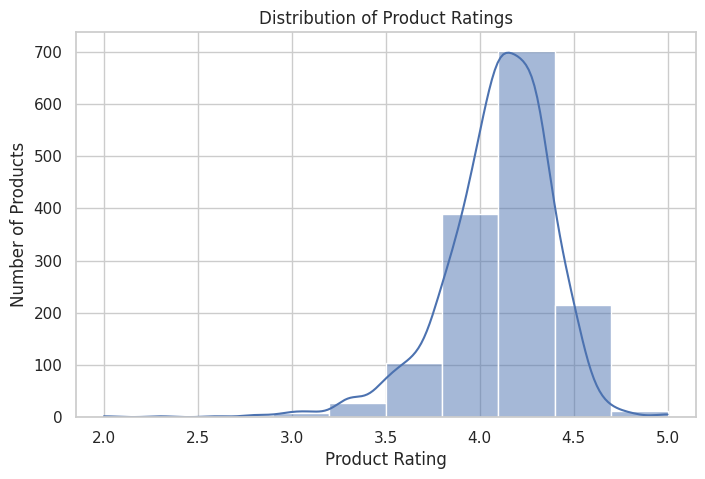

In [ ]:
plt.figure(figsize=(8,5))

sns.histplot(data=df, x='rating', bins=10, kde=True)

plt.title('Distribution of Product Ratings')
plt.xlabel('Product Rating')
plt.ylabel('Number of Products')

plt.show()

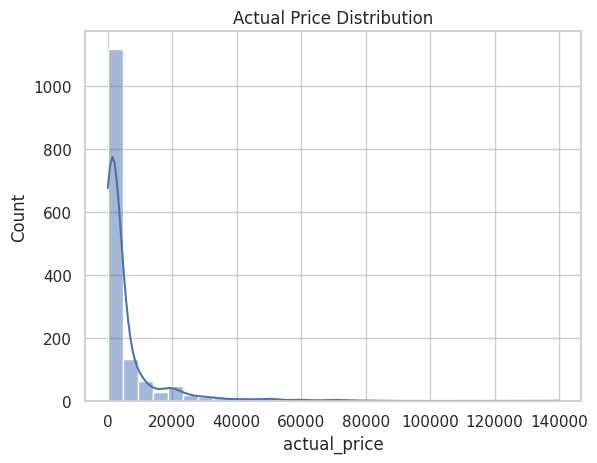

In [ ]:
sns.histplot(data=df, x='actual_price', bins=30, kde=True)
plt.title('Actual Price Distribution')
plt.show()

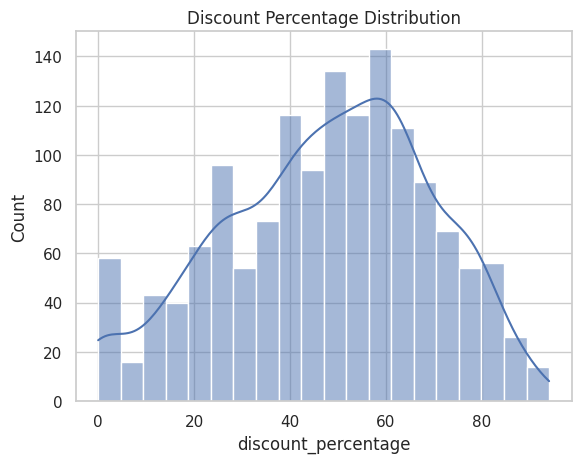

In [ ]:
sns.histplot(data=df, x='discount_percentage', bins=20, kde=True)
plt.title('Discount Percentage Distribution')
plt.show()

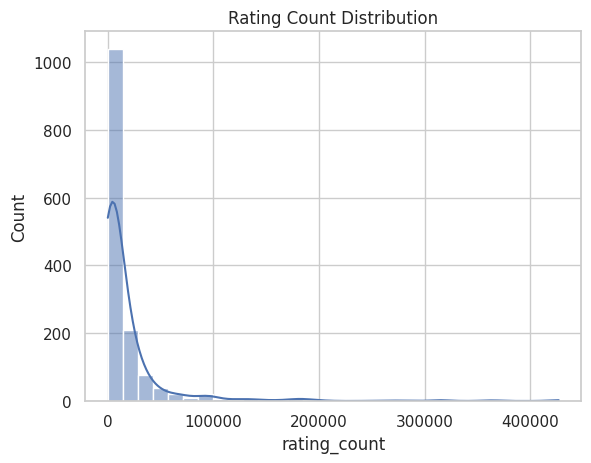

In [ ]:
sns.histplot(data=df, x='rating_count', bins=30, kde=True)
plt.title('Rating Count Distribution')
plt.show()

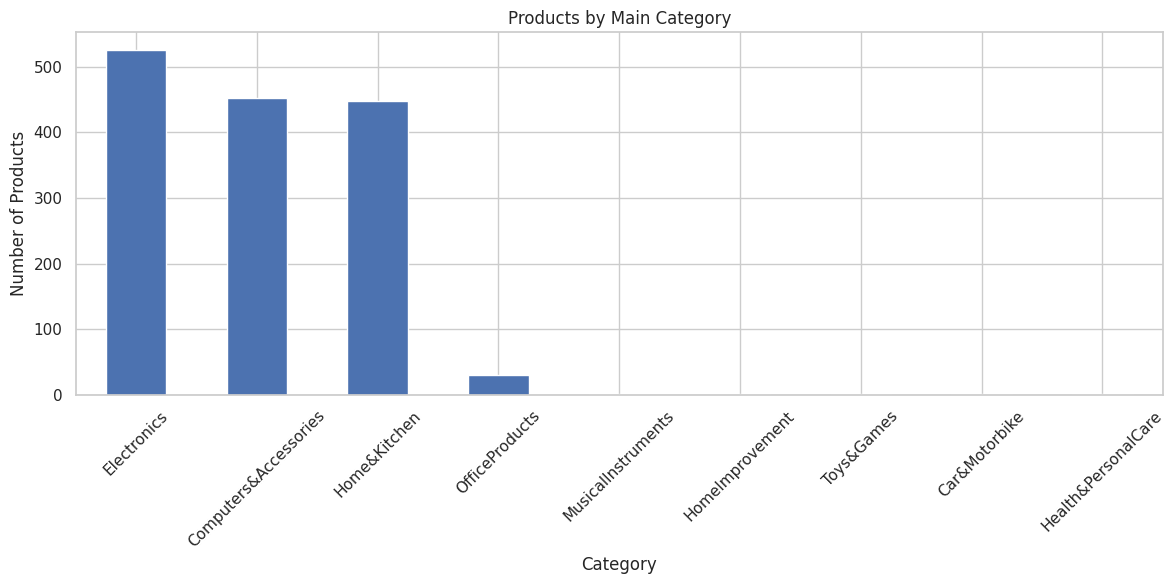

In [ ]:
plt.figure(figsize=(12,6))

df['main_category'].value_counts().plot(kind='bar')

plt.title('Products by Main Category')
plt.xlabel('Category')
plt.ylabel('Number of Products')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
df.head()

,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,user_id,user_name,review_id,review_title,review_content,img_link,product_link,price_difference,savings_percentage,main_category,sub_category
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,399.0,1099.0,64.0,4.2,24269.0,High Compatibility : Compatible With iPhone 12...,"AG3D6O4STAQKAY2UVGEUV46KN35Q,AHMY5CWJMMK5BJRBB...","Manav,Adarsh gupta,Sundeep,S.Sayeed Ahmed,jasp...","R3HXWT0LRP0NMF,R2AJM3LFTLZHFO,R6AQJGUP6P86,R1K...","Satisfied,Charging is really fast,Value for mo...",Looks durable Charging is fine tooNo complains...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...,700.0,63.694268,Computers&Accessories,Accessories&Peripherals
1,B098NS6PVG,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories|Accessories&Peripherals|...,199.0,349.0,43.0,4.0,43994.0,"Compatible with all Type C enabled devices, be...","AECPFYFQVRUWC3KGNLJIOREFP5LQ,AGYYVPDD7YG7FYNBX...","ArdKn,Nirbhay kumar,Sagar Viswanathan,Asp,Plac...","RGIQEG07R9HS2,R1SMWZQ86XIN8U,R2J3Y1WL29GWDE,RY...","A Good Braided Cable for Your Type C Device,Go...",I ordered this cable to connect my phone to An...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Ambrane-Unbreakable-Char...,150.0,42.979943,Computers&Accessories,Accessories&Peripherals
2,B096MSW6CT,Sounce Fast Phone Charging Cable & Data Sync U...,Computers&Accessories|Accessories&Peripherals|...,199.0,1899.0,90.0,3.9,7928.0,【 Fast Charger& Data Sync】-With built-in safet...,"AGU3BBQ2V2DDAMOAKGFAWDDQ6QHA,AESFLDV2PT363T2AQ...","Kunal,Himanshu,viswanath,sai niharka,saqib mal...","R3J3EQQ9TZI5ZJ,R3E7WBGK7ID0KV,RWU79XKQ6I1QF,R2...","Good speed for earlier versions,Good Product,W...","Not quite durable and sturdy,https://m.media-a...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Sounce-iPhone-Charging-C...,1700.0,89.520800,Computers&Accessories,Accessories&Peripherals
3,B08HDJ86NZ,boAt Deuce USB 300 2 in 1 Type-C & Micro USB S...,Computers&Accessories|Accessories&Peripherals|...,329.0,699.0,53.0,4.2,94363.0,The boAt Deuce USB 300 2 in 1 cable is compati...,"AEWAZDZZJLQUYVOVGBEUKSLXHQ5A,AG5HTSFRRE6NL3M5S...","Omkar dhale,JD,HEMALATHA,Ajwadh a.,amar singh ...","R3EEUZKKK9J36I,R3HJVYCLYOY554,REDECAZ7AMPQC,R1...","Good product,Good one,Nice,Really nice product...","Good product,long wire,Charges good,Nice,I bou...",https://m.media-amazon.com/images/I/41V5FtEWPk...,https://www.amazon.in/Deuce-300-Resistant-Tang...,370.0,52.932761,Computers&Accessories,Accessories&Peripherals
4,B08CF3B7N1,Portronics Konnect L 1.2M Fast Charging 3A 8 P...,Computers&Accessories|Accessories&Peripherals|...,154.0,399.0,61.0,4.2,16905.0,[CHARGE & SYNC FUNCTION]- This cable comes wit...,"AE3Q6KSUK5P75D5HFYHCRAOLODSA,AFUGIFH5ZAFXRDSZH...","rahuls6099,Swasat Borah,Ajay Wadke,Pranali,RVK...","R1BP4L2HH9TFUP,R16PVJEXKV6QZS,R2UPDB81N66T4P,R...","As good as original,Decent,Good one for second...","Bought this instead of original apple, does th...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Portronics-Konnect-POR-1...,245.0,61.403509,Computers&Accessories,Accessories&Peripherals


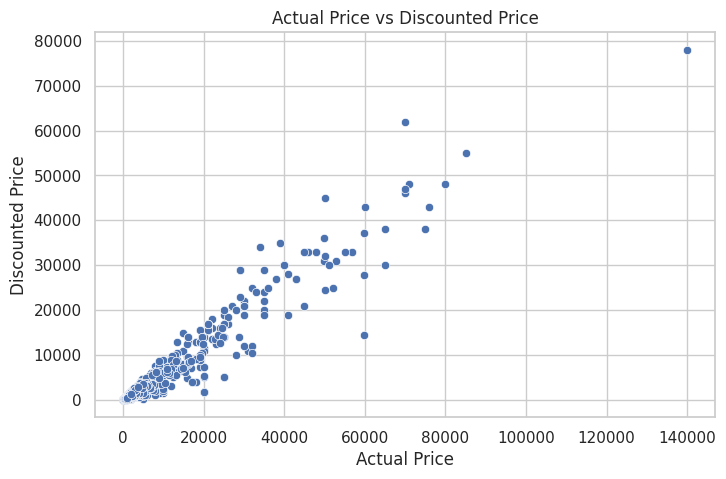

In [ ]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x='actual_price',
    y='discounted_price'
)

plt.title('Actual Price vs Discounted Price')
plt.xlabel('Actual Price')
plt.ylabel('Discounted Price')

plt.show()

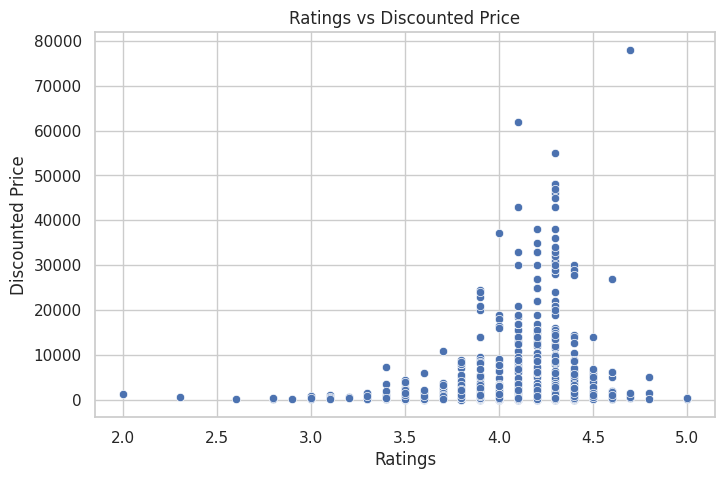

In [ ]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x='rating',
    y='discounted_price'
)

plt.title('Ratings vs Discounted Price')
plt.xlabel('Ratings')
plt.ylabel('Discounted Price')

plt.show()

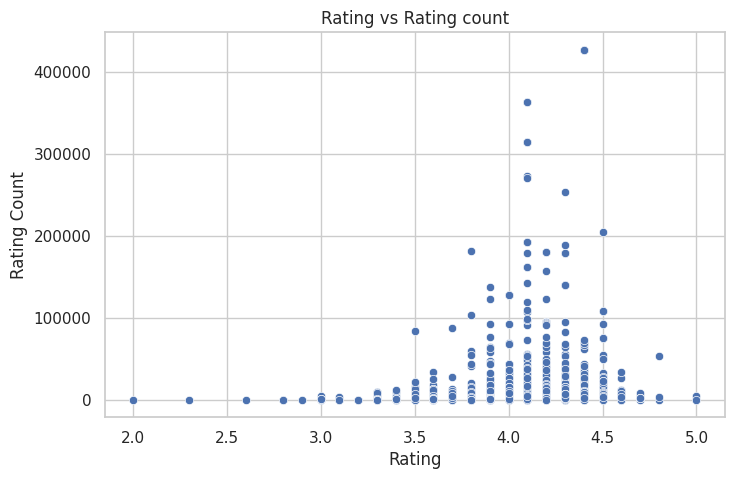

In [ ]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x='rating',
    y='rating_count'
)

plt.title('Rating vs Rating count')
plt.xlabel('Rating')
plt.ylabel('Rating Count')

plt.show()

In [ ]:
avg_rating = df.groupby('main_category')['rating'].mean().sort_values(ascending=False)



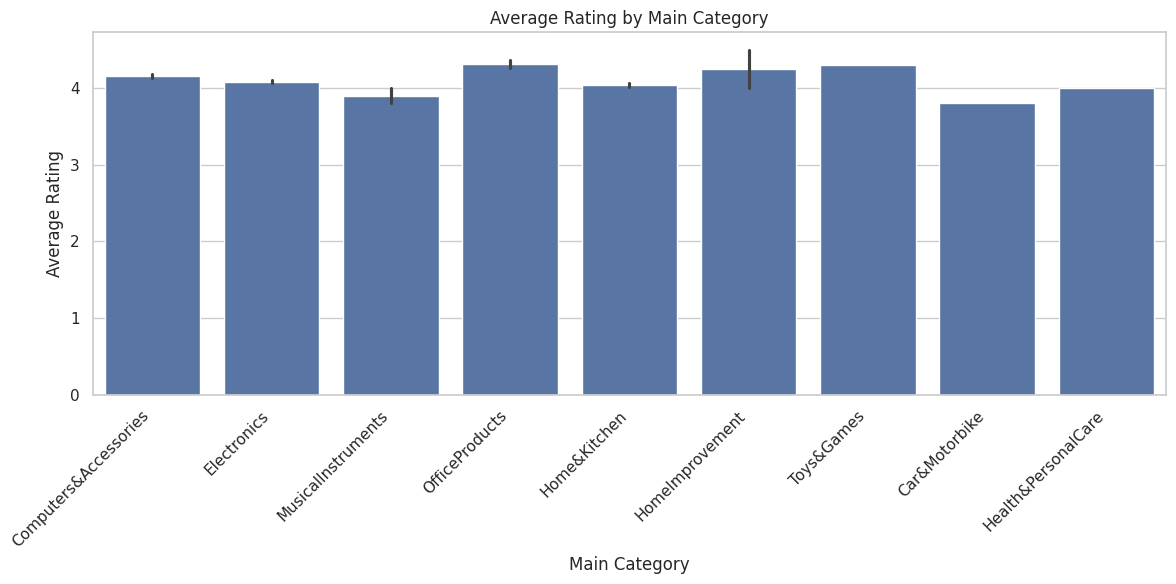

In [ ]:
plt.figure(figsize=(12,6))
sns.barplot(x=df['main_category'], y=df['rating'])
plt.title('Average Rating by Main Category')
plt.xlabel('Main Category')
plt.ylabel('Average Rating')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

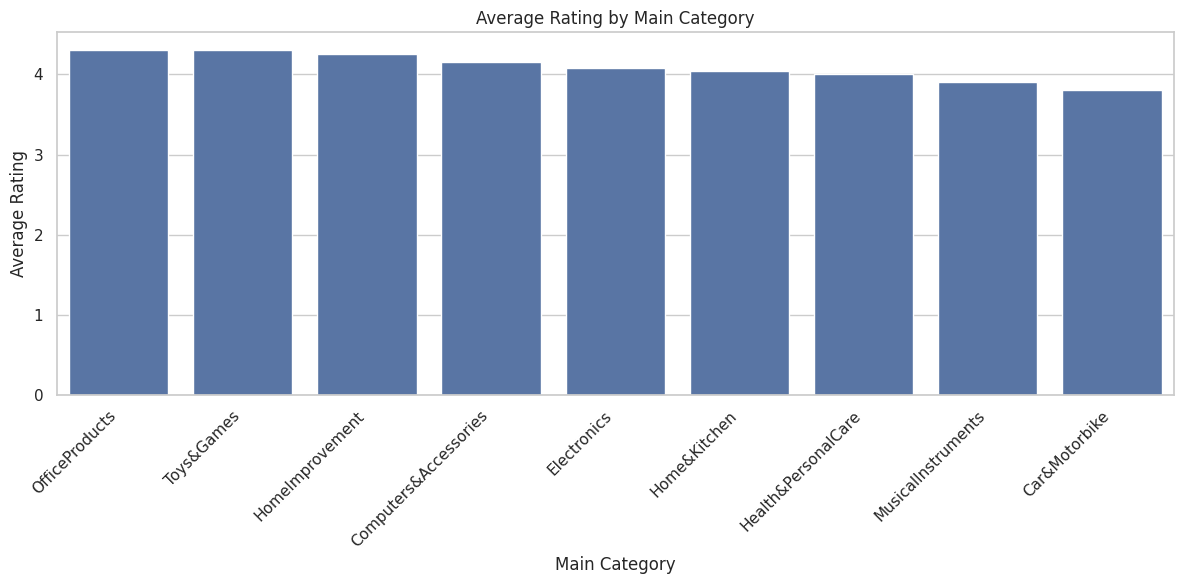

In [ ]:
plt.figure(figsize=(12,6))
sns.barplot(x=avg_rating.index, y=avg_rating.values)
plt.title('Average Rating by Main Category')
plt.xlabel('Main Category')
plt.ylabel('Average Rating')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

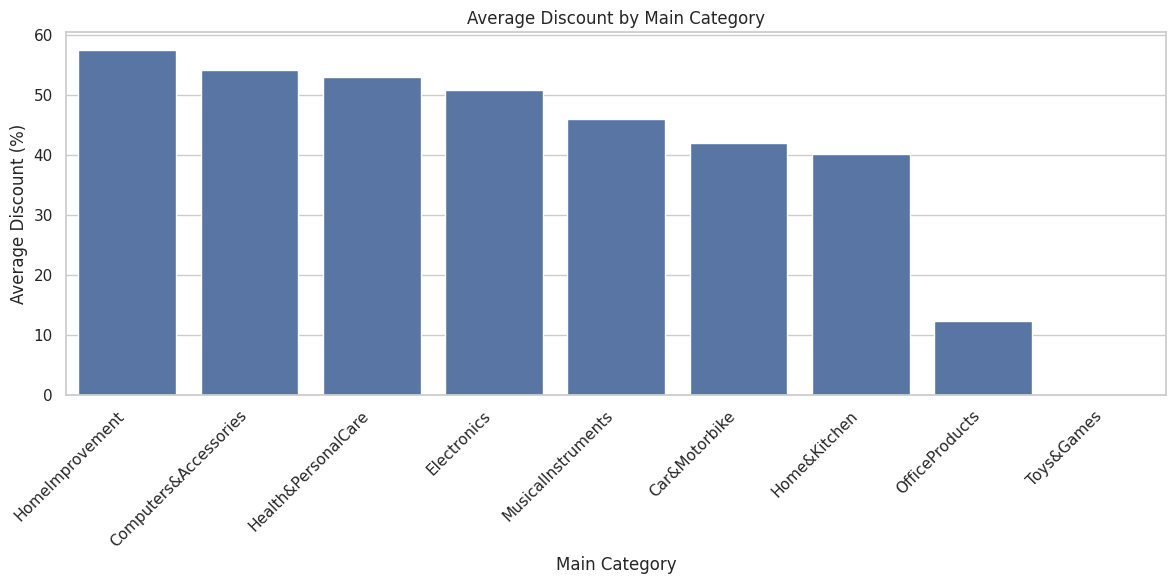

In [ ]:
plt.figure(figsize=(12,6))

avg_discount = df.groupby('main_category')['discount_percentage'].mean().sort_values(ascending=False)

sns.barplot(x=avg_discount.index, y=avg_discount.values)

plt.title('Average Discount by Main Category')
plt.xlabel('Main Category')
plt.ylabel('Average Discount (%)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

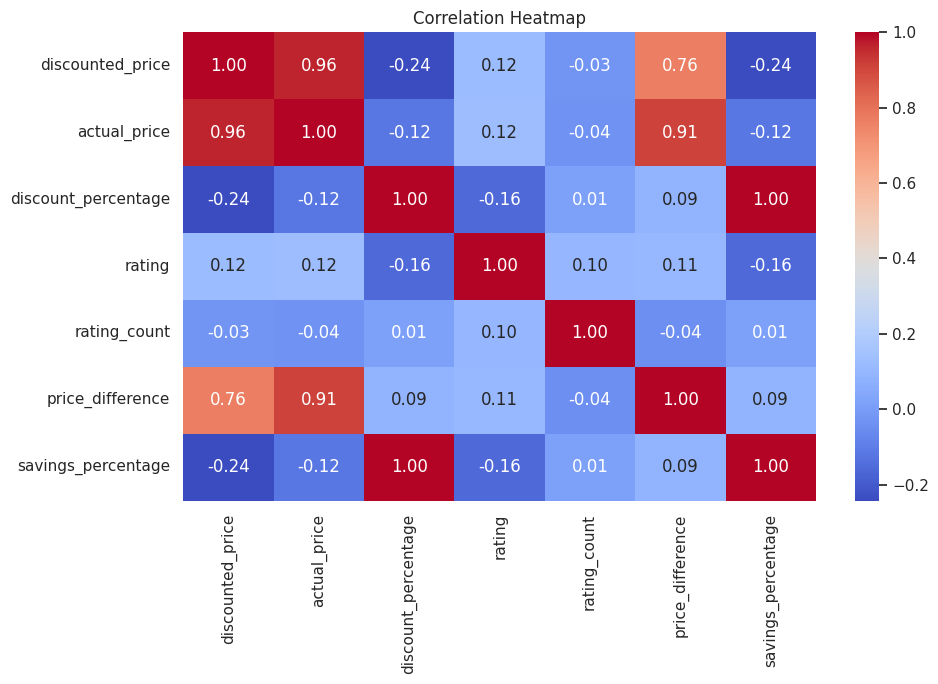

In [ ]:
plt.figure(figsize=(10,7))

numeric_df = df.select_dtypes(include=np.number)

correlation = numeric_df.corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

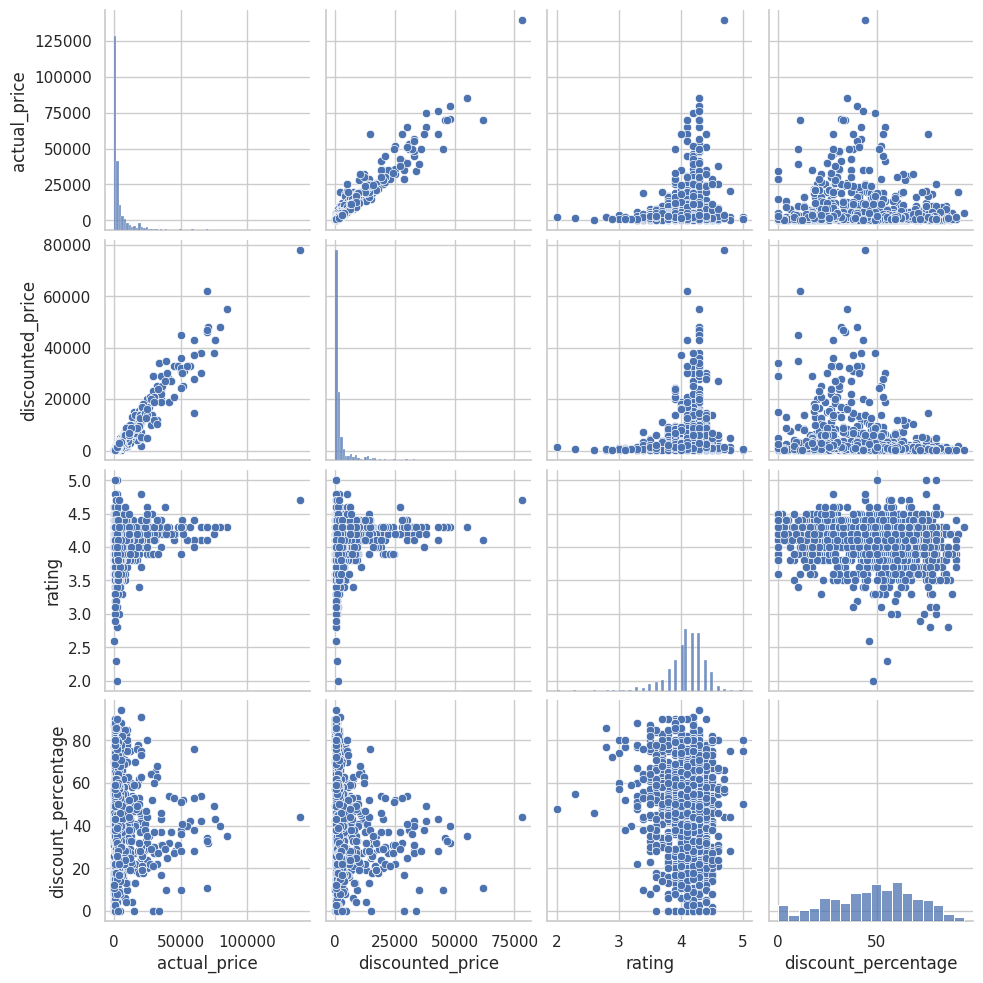

In [ ]:
selected_columns = [
    'actual_price',
    'discounted_price',
    'rating',
    'discount_percentage'
]

sns.pairplot(df[selected_columns].dropna())

plt.show()

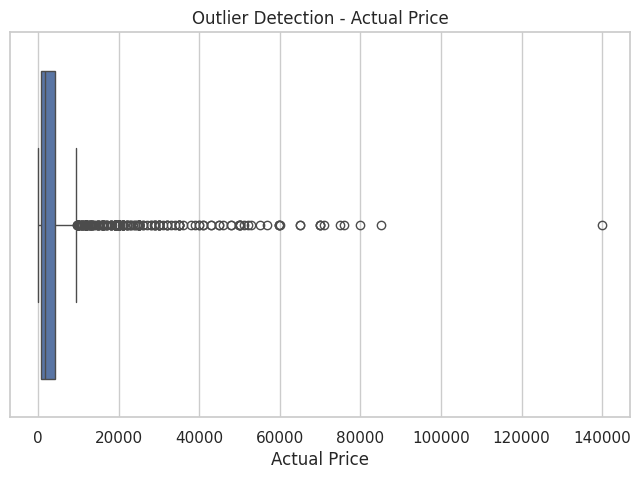

In [ ]:
plt.figure(figsize=(8,5))

sns.boxplot(x=df['actual_price'])

plt.title('Outlier Detection - Actual Price')
plt.xlabel('Actual Price')
plt.show()

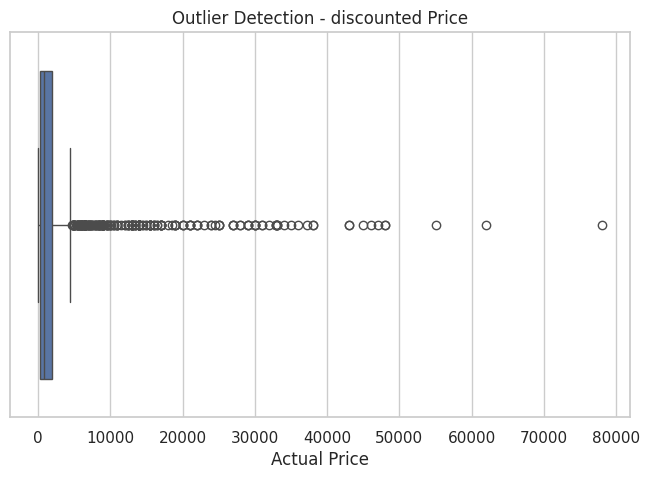

In [ ]:
plt.figure(figsize=(8,5))

sns.boxplot(x=df['discounted_price'])

plt.title('Outlier Detection - discounted Price')
plt.xlabel('Actual Price')
plt.show()

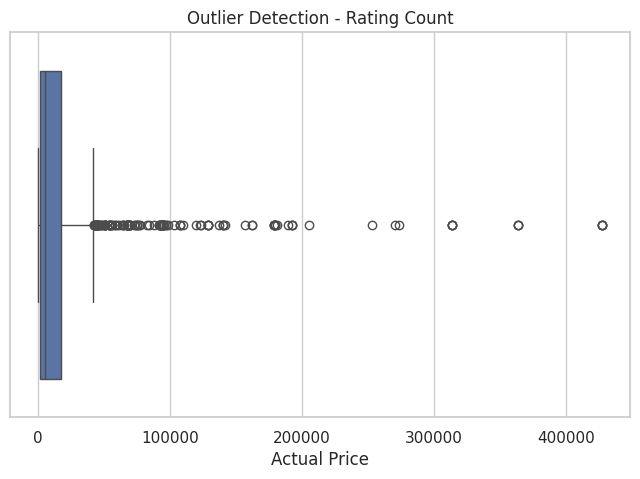

In [ ]:
plt.figure(figsize=(8,5))

sns.boxplot(x=df['rating_count'])

plt.title('Outlier Detection - Rating Count')
plt.xlabel('Actual Price')
plt.show()

In [ ]:
Q1 = df['actual_price'].quantile(0.25)
Q3 = df['actual_price'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df[
    (df['actual_price'] < lower_limit) |
    (df['actual_price'] > upper_limit)
]

print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)
print("Total Outliers:", len(outliers))

Lower Limit: -4442.5
Upper Limit: 9537.5
Total Outliers: 213


In [ ]:
top_discount=df.sort_values(by='discount_percentage',ascending=False).head(10)
display(top_discount[['product_name','actual_price']])

,product_name,actual_price
695,"rts [2 Pack] Mini USB C Type C Adapter Plug, T...","₹4,999"
364,"Fire-Boltt Ninja Call Pro Plus 1.83"" Smart Wat...","₹19,999"
380,"Fire-Boltt Ninja Call Pro Plus 1.83"" Smart Wat...","₹19,999"
368,"Fire-Boltt Ninja Call Pro Plus 1.83"" Smart Wat...","₹19,999"
334,"Fire-Boltt Ninja Call Pro Plus 1.83"" Smart Wat...","₹19,999"
372,"Fire-Boltt Ninja Call Pro Plus 1.83"" Smart Wat...","₹19,999"
557,LAPSTER 12pcs Spiral Cable Protectors for Char...,₹999
1026,beatXP Kitchen Scale Multipurpose Portable Ele...,"₹1,999"
920,"Silicone Rubber Earbuds Tips, Eartips, Earpads...",₹999
644,Sounce Spiral Charger Cable Protector Data Cab...,₹999


In [ ]:
top_expensive=df.sort_values(by='actual_price',ascending=False).head(10)
display(top_expensive[['product_name','actual_price']])

,product_name,actual_price
249,Sony Bravia 164 cm (65 inches) 4K Ultra HD Sma...,139900.0
255,VU 164 cm (65 inches) The GloLED Series 4K Sma...,85000.0
283,LG 139 cm (55 inches) 4K Ultra HD Smart LED TV...,79990.0
1354,LG 1.5 Ton 5 Star AI DUAL Inverter Split AC (C...,75990.0
568,"Samsung Galaxy S20 FE 5G (Cloud Navy, 8GB RAM,...",74999.0
192,Samsung 138 cm (55 inches) Crystal 4K Neo Seri...,70900.0
325,OnePlus 163.8 cm (65 inches) U Series 4K LED S...,69999.0
332,MI 138.8 cm (55 inches) 5X Series 4K Ultra HD ...,69999.0
276,Samsung 138 cm (55 inches) Crystal 4K Series U...,69900.0
108,VU 139 cm (55 inches) The GloLED Series 4K Sma...,65000.0


In [ ]:
popular_products=df.sort_values(by='rating_count',ascending=False).head(10)
display(popular_products[['product_name','rating','rating_count']])

,product_name,rating,rating_count
1279,Eureka Forbes car Vac 100 Watts Powerful Sucti...,|,992
750,Eveready Red 1012 AAA Batteries - Pack of 10,4.3,989
977,Sennheiser CX 80S in-Ear Wired Headphones with...,4.1,"98,250"
1059,Pigeon 1.5 litre Hot Kettle and Stainless Stee...,3.7,976
151,Zoul USB Type C Fast Charging 3A Nylon Braided...,4.3,974
32,Zoul USB C 60W Fast Charging 3A 6ft/2M Long Ty...,4.3,974
823,Zoul USB C 60W Fast Charging 3A 6ft/2M Long Ty...,4.3,974
536,boAt Rockerz 400 Bluetooth On Ear Headphones W...,4.1,"97,175"
918,boAt Rockerz 400 Bluetooth On Ear Headphones W...,4.1,"97,174"
1165,Kitchenwell 18Pc Plastic Food Snack Bag Pouch ...,4,97
